# Projet Recherche Opérationnelle

**Classe :** FISA A3 - Informatique  
**Groupe :** NOIRET Robin, LALOUANI Jalil, KLEBER Mattéo, CAPARROS Martin, UPJOHN Max  
**Période :** 03/2026 - 04/2026

---


# 1 - Contexte & Identification du problème

## 1.1 Cas d'application

Dans le cadre de l'appel à projets de l'**ADEME** sur la mobilité intelligente, notre bureau d'études **CesiCDP** a choisi de tester ses algorithmes d'optimisation sur un scénario concret et d'actualité : **la logistique de l'économie circulaire en milieu urbain dense**.

### Scénario expérimental
Un véhicule logistique part d'un centre de tri situé en périphérie (notre dépôt).</br> Sa mission quotidienne est double :
1. **Livrer** des équipements volumineux reconditionnés (ex: gros électroménager, pompes à chaleur) dans divers points relais ou chez des particuliers.

2. **Collecter** les anciens appareils en fin de vie (DEEE) pour les rapatrier au centre de tri afin d'y être recyclés.

### Intégration de nos contraintes de test
Pour valider la robustesse de notre modèle face à la réalité opérationnelle, notre environnement de simulation intègre deux contraintes physiques et réglementaires strictes :

* **Dépendances entre visites :** Il est physiquement impossible de charger un ancien équipement encombrant si le nouveau n'a pas encore été déchargé. L'algorithme doit donc garantir une **précédence** : la livraison d'un point A doit obligatoirement être effectuée avant la collecte au point B associé.</br></br>

* **La difficulté & l'inaccessibilité des routes :** Le réseau routier simulé intègre les nouvelles politiques d'urbanisme. L'algorithme devra trouver le trajet optimal en prenant en compte :
    * Des routes à coût majoré (zones de travaux urbains causant des détours ou des ralentissements).
    * Des routes strictement interdites (Zones à Faibles Émissions - ZFE inaccessibles, ou rues piétonnes/ponts avec restrictions de gabarit).

## 1.2 Identification du problème

### Périmètre de l'étude
L'étude se concentre sur **une tournée quotidienne**, réalisée par **un unique véhicule**, au départ et au retour d'**un dépôt unique**. Les aspects tels que la flotte multi-véhicules, la gestion des stocks au dépôt ou la planification sur plusieurs jours sont volontairement exclus du périmètre afin de concentrer l'analyse sur la structure combinatoire du routage sous contraintes.

### Reformulation du besoin
Derrière le scénario opérationnel décrit en 1.1 se cache un besoin algorithmique clair : **déterminer l'ordre de visite d'un ensemble de points d'arrêt** (livraisons et collectes) qui permette de réaliser l'intégralité de la tournée dans les meilleures conditions possibles, tout en respectant des règles de précédence et des restrictions de circulation imposées par le réseau routier.

### Objectif de l'étude
L'objectif d'optimisation retenu est la **minimisation de la distance totale parcourue** sur l'ensemble de la tournée. Ce critère sert de proxy direct aux enjeux soulevés par l'ADEME : réduction de la consommation énergétique, des émissions de gaz à effet de serre, et du temps de trajet du véhicule.

### Rattachement à un problème connu
Ce problème est une **variante du problème du voyageur de commerce** (*Travelling Salesman Problem*, TSP)[$^5$](#52-références-scientifiques) [$^6$](#52-références-scientifiques). La formulation classique du TSP, à savoir trouver le cycle hamiltonien de poids minimal dans un graphe pondéré correspond exactement à la structure de notre tournée. Les deux contraintes que nous ajoutons (arêtes interdites/coûteuses et précédences) en font une instance enrichie.

</br>

**Ce document pose les fondations théoriques de notre problème.** </br></br> La modélisation de ce problème de routage sous nos contraintes spécifiques choisies ainsi que la démonstration de son **explosion combinatoire** (NP-difficulté) justifieront, pour la suite du projet, l'implémentation de méthodes de résolution **approchées** capables de fournir des plans de tournée viables dans des temps de calcul optimisés.

# 2 - Définition mathématique du problème

## 2.1 Données du problème

On modélise le réseau routier par un graphe orienté pondéré :

$$G = (V, E, c')$$

avec :

- $V = \{v_0, v_1, \ldots, v_n\}$ : l'ensemble des **nœuds** (villes), où $v_0$ désigne le **dépôt** (point de départ et d'arrivée)
- $E = \{(i,j) \mid i \in V,\ j \in V,\ i \neq j\}$ : l'ensemble des **arêtes** (routes)
- $c'_{ij} = \alpha_{ij} \cdot c_{ij}$ : la **fonction de coût**, associant à chaque arête une distance. On ajoute une notion de coefficient (BigM)
> $\quad \quad \quad \alpha_{ij} = \begin{cases} 1 & \text{route classique} \\ [2,\ 10] & \text{route coûteuse} \\ [1000,\ 10000] & \text{route interdite} \end{cases}$

On définit également les ensembles suivants pour modéliser nos contraintes supplémentaires :

- $F \subseteq E$ : l'ensemble des **arêtes interdites** (routes bloquées, trop coûteuses ou inaccessibles)
- $D \subseteq V^2$ : l'ensemble des **paires de dépendance** de la forme $(i, j)$, signifiant que la ville $i$ doit être visitée avant la ville $j$ (livraison avant collecte)

## 2.2 Variables de décision

**Variables binaires de sélection des arêtes :**

$$x_{ij} \in \{0, 1\} \quad \forall (i,j) \in E$$

$x_{ij} = 1$ si et seulement si l'arête $(i,j)$ est empruntée dans la tournée, $0$ sinon.

**Variables de position (rang dans la tournée) :**

$$p_i \in \{1, \ldots, n\} \quad \forall i \in V \setminus \{v_0\}$$

$p_i$ représente le rang (ordre de passage) de la ville $i$ dans la tournée.

## 2.3 Fonction objectif

On cherche à **minimiser la distance totale** de la tournée :

$$\min \sum_{i \in V} \sum_{\substack{j \in V \\ j \neq i}} c'_{ij} \cdot x_{ij}$$

## 2.4 Contraintes

#### (C1) Chaque ville est visitée exactement une fois

$$\sum_{j \in V,\ j \neq i} x_{ij} = 1 \quad \forall i \in V  \quad \quad \quad

\sum_{i \in V,\ i \neq j} x_{ij} = 1 \quad \forall j \in V$$

#### (C2) Coût ou restriction de passage sur certaines arêtes

Certaines routes peuvent être dégradées (travaux, détours) ou totalement inaccessibles. Plutôt qu'une interdiction stricte, on modélise ces restrictions par un **coefficient de pénalité** $\alpha_{ij}$ appliqué au coût de chaque arête :

$$c'_{ij} = \alpha_{ij} \cdot c_{ij}$$

$$\alpha_{ij} = \begin{cases} 1 & \text{route classique} \\ [2,\ 10] & \text{route coûteuse} \\ [1000,\ 10000] & \text{route interdite} \end{cases}$$

> **Note :** Les arêtes "interdites" ne sont pas exclues par une contrainte dure, mais leur coût ajusté garantit qu'elles ne seront jamais empruntées par une solution optimale, étant donné l'échelle classique des coûts ($c_{ij} \in [1, 10]$).

#### (C3) Contraintes de dépendances de visite

Pour chaque paire de dépendance $(i, j) \in D$, la ville $i$ doit être visitée **avant** la ville $j$ :

$$p_i + 1 \leq p_j \quad \forall (i,j) \in D$$

> **Note :** Cette formule garantit un écart d'au moins une position entre les deux villes dans l'ordre de visite.

#### (C4) Élimination des sous-tours — Formulation MTZ

Pour éliminer les sous-tours (circuits ne passant pas par le dépôt), on utilise la formulation de Miller-Tucker-Zemlin (MTZ)[$^7$](#52-références-scientifiques) [$^8$](#52-références-scientifiques)  :

$$p_i - p_j + n \cdot x_{ij} \leq n - 1 \quad \forall (i,j) \in E,\ i \neq v_0,\ j \neq v_0$$

**Explication :**
- Si l'arête $(i,j)$ est utilisée ($x_{ij} = 1$) : la contrainte devient $p_i - p_j \leq -1$, soit $p_j \geq p_i + 1$. La ville $j$ est donc visitée **immédiatement après** la ville $i$ dans la tournée, ce sont donc deux villes consécutives. (cette contrainte représente l'élimination des sous-tours et non la dépendance de visite)
- Si l'arête $(i,j)$ n'est pas utilisée ($x_{ij} = 0$) : la contrainte devient $p_i - p_j \leq n - 1$, ce qui est toujours satisfait puisque les rangs appartiennent à $\{1, \dots, n\}$. La contrainte est relâchée.

## 2.5 Récapitulation (programmation linéaire)

On formule le problème comme un **programme linéaire en nombres entiers** (*Integer Linear Programming*, ILP). Les variables $x_{ij}$ sont binaires et les variables $p_i$ sont entières. Toutes les contraintes sont linéaires en ces variables.

$$
\text{PL} : \begin{cases}
\min & \displaystyle\sum_{i \in V} \sum_{\substack{j \in V \\ j \neq i}} c'_{ij} \cdot x_{ij} \\[10pt]
\ & \displaystyle\sum_{j \in V,\, j \neq i} x_{ij} = 1 \quad \forall i \in V \quad \text{(C1a)} \\[10pt]
& \displaystyle\sum_{i \in V,\, i \neq j} x_{ij} = 1 \quad \forall j \in V \quad \text{(C1b)} \\[10pt]
& p_i + 1 \leq p_j \quad \forall (i,j) \in D \quad \text{(C3)} \\[10pt]
& p_i - p_j + n \cdot x_{ij} \leq n - 1 \quad \forall (i,j) \in E,\ i \neq v_0,\ j \neq v_0 \quad \text{(C4)} \\[10pt]
& x_{ij} \in \{0, 1\} \\[10pt]
& p_i \in \{1, \ldots, n\} \\[10pt]
\end{cases}
$$

# 3 - Analyse de la complexité

La justification de la complexité de notre problème est primordiale pour orienter nos futurs choix d'implémentation. Pour ce faire, nous allons procéder par étapes, en partant d'un problème fondamental de la théorie des graphes pour arriver à notre cas d'usage logistique.

## 3.1. Le point de départ : Le problème du Cycle Hamiltonien (HC)

Le problème du Cycle Hamiltonien consiste à déterminer si, dans un graphe donné, il existe un cycle passant par chaque sommet exactement une fois.Ce problème de décision a été formellement classé comme NP-complet par Richard M. Karp en 1972 (il fait partie de ses 21 problèmes originaux). Cela signifie qu'il n'existe, à ce jour, aucun algorithme capable de le résoudre en un temps polynomial.

Référence : Karp, R. M. (1972). Reducibility among combinatorial problems. In Complexity of computer computations (pp. 85-103). Springer, Boston, MA.[$^{10}$](#52-références-scientifiques)

## 3.2. Preuve de la complexité du TSP par réduction polynomiale

Le problème de décision du Voyageur de Commerce (TSP) consiste à savoir s'il existe une tournée visitant toutes les villes avec un coût total inférieur ou égal à une limite $L$. Nous pouvons démontrer que le TSP est au moins aussi difficile que le Cycle Hamiltonien par une réduction polynomiale ($HC \leq_p TSP$). Soit une instance du problème du Cycle Hamiltonien définie par un graphe $G = (V, E)$. Nous construisons une instance du TSP de la manière suivante : Nous créons un graphe complet $G' = (V, E', c)$ ayant les mêmes sommets que $G$.Nous définissons la fonction de coût $c_{ij}$ pour chaque arête $(i, j)$ dans $E'$ :$$c_{ij} = \begin{cases} 1 & \text{si } (i, j) \in E \\ 2 & \text{si } (i, j) \notin E \end{cases}$$ Nous fixons notre limite de coût à $L = |V|$ (le nombre de sommets). Équivalence :Si $G$ possède un cycle hamiltonien, alors en suivant les mêmes arêtes dans $G'$, chaque arête aura un coût de $1$. Le coût total de la tournée sera exactement $|V|$. Inversement, si $G'$ possède une tournée de coût inférieur ou égal à $|V|$, cela signifie que la tournée n'emprunte que des arêtes de coût $1$ (puisqu'il y a $|V|$ arêtes dans la tournée). Donc, toutes ces arêtes existent dans le graphe d'origine $G$, formant ainsi un cycle hamiltonien.La transformation du graphe $G$ en $G'$ se fait en temps polynomial (en parcourant toutes les paires de sommets, soit $O(|V|^2)$). Le problème HC se réduisant polynomialement au problème TSP, le TSP est donc NP-complet.

## 3.3. Application à notre problème d'optimisation

Notre modélisation, qui répond aux exigences de l'ADEME, inclut des restrictions d'arêtes et des contraintes de précédence. Il s'agit d'une variante du problème de voyageur du commerce.Pour prouver que notre problème d'optimisation est NP-difficile, nous utilisons le principe de restriction : Considérons une instance de notre problème logistique où nous relâchons volontairement nos contraintes spécifiques : Aucune arête n'est interdite : $E_{interdit} = \emptyset$ Aucune dépendance n'est requise entre les villes : $P = \emptyset$ Dans ces conditions restrictives, notre problème devient strictement identique au TSP d'optimisation classique. Puisque notre problème général contient le TSP (qui est NP-difficile) comme un cas particulier, notre problème est par définition au moins aussi complexe que le TSP.

# 4 - Bibliographie

1. 
2. [**Problème de vendeur de voyages. (s. d.).** *Google For Developers.*](https://developers.google.com/optimization/routing/tsp?hl=fr) - visité le 09/04/2026
3. [**Problème d’itinéraire. (s. d.).** *Google For Developers.*](https://developers.google.com/optimization/routing/vrp?hl=fr) - visité le 09/04/2026
4. 
5. [**Dantzig, G. B., & Ramser, J. H. (1959).** *The Truck Dispatching Problem*. Management Science, 6(1), 80-91.](https://pubsonline.informs.org/doi/10.1287/mnsc.6.1.80)
6. [**Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960).** *Integer Programming Formulation of Traveling Salesman Problems*. Journal of the ACM (JACM), 7(4), 326-329.](https://dl.acm.org/doi/10.1145/321043.321046)
7. [**Diego. (2020, 24 juin).** *Traveling Salesman Problem (TSP) with Miller-Tucker-Zemlin (MTZ) in CPLEX/OPL – CoEnzyme.*](https://co-enzyme.fr/blog/traveling-salesman-problem-tsp-in-cplex-opl-with-miller-tucker-zemlin-mtz-formulation/)
8. [**Teaching Integer Programming Formulations Using the Traveling Salesman Problem. (2003).** *SIAM REVIEW, 4.*](https://mate.unipv.it/~gualandi/famo2conti/papers/teaching_tsp.pdf)
9. [**Garey, M. R., & Johnson, D. S. (1979).** *Computers and Intractability: A Guide to the Theory of NP-Completeness. W. H. Freeman & Co.*](https://perso.limos.fr/~palafour/PAPERS/PDF/Garey-Johnson79.pdf)
10. [**Karp, R. M. (1972).** *Reducibility among combinatorial problems*. In Complexity of computer computations (pp. 85-103). Springer, Boston, MA.](https://www.cs.umd.edu/~gasarch/BLOGPAPERS/Karp.pdf)

____

# 5 - Méthodes de résolution

In [1]:
from pulp import *                                  # Modélisation et résolution PLNE
import numpy as np                                  # Calcul numérique et tableaux
from scipy.spatial.distance import cdist            # Calcul vectorisé des distances
import matplotlib.pyplot as plt                     # Visualisation du graphe et des tournées
from matplotlib.collections import LineCollection   # Tracer efficacement plusieurs arêtes à la fois
import time                                         # Mesure des temps d'exécution
from matplotlib.lines import Line2D                 # Lignes personnalisées pour la légende
from ipywidgets import IntProgress                  # Barre de progression
from IPython.display import display                 # Affichage des widgets
import pandas as pd

### Fonctions utiles

In [ ]:
def generer_instance(
    n,
    x_max=500,
    y_max=500,
    seed=None,
    pct_travaux=0.1,
    pct_interdites=0.05,
    pct_dependances=0.05,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
):
    if seed is not None:
        np.random.seed(seed)
    
    x_coords = np.random.randint(50, x_max, size=n)
    y_coords = np.random.randint(50, y_max, size=n)
    coords = np.column_stack((x_coords, y_coords))

    dist = np.round(cdist(coords, coords, metric='euclidean') * 100).astype(int)
    couts = dist.copy()

    aretes = [(i, j) for i in range(n) for j in range(i + 1, n)]
    if not aretes:
        return coords.tolist(), couts.tolist(), [], [], []

    pct_travaux = pct_travaux / 100 if pct_travaux > 1 else pct_travaux
    pct_interdites = pct_interdites / 100 if pct_interdites > 1 else pct_interdites
    pct_dependances = pct_dependances / 100 if pct_dependances > 1 else pct_dependances

    total_aretes = len(aretes)
    nb_travaux = min(total_aretes, int(round(pct_travaux * total_aretes)))
    nb_interdites = min(total_aretes - nb_travaux, int(round(pct_interdites * total_aretes)))

    indices = np.arange(total_aretes)
    aretes_travaux = []
    aretes_interdites = []

    if nb_travaux > 0:
        indices_travaux = np.random.choice(indices, size=nb_travaux, replace=False)
        for idx in indices_travaux:
            i, j = aretes[idx]
            coef = np.random.uniform(coef_travaux_min, coef_travaux_max)
            valeur = int(round(dist[i, j] * coef))
            couts[i, j] = couts[j, i] = valeur
            aretes_travaux.append((i, j))
        indices = np.setdiff1d(indices, indices_travaux)

    if nb_interdites > 0:
        indices_interdites = np.random.choice(indices, size=nb_interdites, replace=False)
        for idx in indices_interdites:
            i, j = aretes[idx]
            penalite = int(round(np.random.uniform(coef_interdit_min, coef_interdit_max)))
            valeur = dist[i, j] + penalite
            couts[i, j] = couts[j, i] = valeur
            aretes_interdites.append((i, j))

    nb_dependances = max(0, int(round(pct_dependances * n)))
    dependances = []
    if nb_dependances > 0 and n > 1:
        for _ in range(nb_dependances * 5):
            if len(dependances) >= nb_dependances:
                break
            i, j = np.random.randint(1, n, 2)
            i, j = int(i), int(j)
            if i != j and (i, j) not in dependances:
                dependances.append((i, j))

    return coords.tolist(), couts.tolist(), aretes_travaux, aretes_interdites, dependances

In [3]:
def valider_contraintes(tournee, aretes_interdites=None, dependances=None):
    positions = {ville: idx for idx, ville in enumerate(tournee)}
    
    aretes_interdites_violees = []
    if aretes_interdites:
        aretes_interdites_set = set((min(i, j), max(i, j)) for i, j in aretes_interdites)
        for k in range(len(tournee)):
            i, j = tournee[k], tournee[(k + 1) % len(tournee)]
            if (min(i, j), max(i, j)) in aretes_interdites_set:
                aretes_interdites_violees.append((i, j))
    
    dependances_violees = []
    if dependances:
        for i, j in dependances:
            pos_i = positions.get(i)
            pos_j = positions.get(j)
            if pos_i is not None and pos_j is not None and pos_i >= pos_j:
                dependances_violees.append((i, j))
    
    return {
        'aretes_interdites_violees': aretes_interdites_violees,
        'dependances_violees': dependances_violees,
        'valide': len(aretes_interdites_violees) == 0 and len(dependances_violees) == 0
    }

In [4]:
def resoudre_tsp_plne(couts, coords=None, aretes_travaux=None, aretes_interdites=None, dependances=None, verbose=True):
    n = len(couts)
    villes = range(n)

    prob = LpProblem("TSP_Couts_Variables", LpMinimize)

    x = LpVariable.dicts("x", (villes, villes), cat="Binary")
    p = LpVariable.dicts("p", range(1, n), lowBound=1, upBound=n - 1, cat="Continuous")

    prob += lpSum(couts[i][j] * x[i][j] for i in villes for j in villes if i != j)

    for i in villes:
        prob += lpSum(x[i][j] for j in villes if j != i) == 1
        prob += lpSum(x[j][i] for j in villes if j != i) == 1

    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                prob += p[i] - p[j] + n * x[i][j] <= n - 1

    if dependances:
        for i, j in dependances:
            if 0 < i < n and 0 < j < n and i != j:
                prob += p[i] - p[j] <= -1
            elif i == 0 and 0 < j < n:
                pass
            elif 0 < i < n and j == 0:
                prob += p[i] >= 1

    debut = time.time()
    prob.solve(PULP_CBC_CMD(msg=0))
    duree = time.time() - debut

    if LpStatus[prob.status] != "Optimal":
        if verbose:
            print(f"Statut du solveur : {LpStatus[prob.status]}")
        return None, None, duree

    cout = value(prob.objective)

    tournee = [0]
    ville_courante = 0
    for _ in range(n - 1):
        for j in villes:
            if j != ville_courante and value(x[ville_courante][j]) > 0.5:
                tournee.append(j)
                ville_courante = j
                break

    validation = valider_contraintes(tournee, aretes_interdites, dependances)

    if verbose:
        print(f"Statut : {LpStatus[prob.status]}")
        print(f"Coût optimal : {cout:.2f}")
        print(f"Tournée : {tournee + [tournee[0]]}")
        print(f"Temps de résolution : {duree:.4f} s")
        
        if validation['aretes_interdites_violees']:
            print(f"ATTENTION : {len(validation['aretes_interdites_violees'])} arête(s) interdite(s) utilisée(s) !")
            for i, j in validation['aretes_interdites_violees']:
                print(f"  {i} -> {j}")
        else:
            print("Aucune arête interdite utilisée")
        
        if validation['dependances_violees']:
            print(f"ATTENTION : {len(validation['dependances_violees'])} dépendance(s) violée(s) !")
            positions = {ville: idx for idx, ville in enumerate(tournee)}
            for i, j in validation['dependances_violees']:
                print(f"  {i} -> {j} : position {positions[i]} >= position {positions[j]}")
        else:
            print("Toutes les dépendances sont respectées")

    return tournee, cout, duree

In [5]:
def afficher_tournee(coords, tournee, dist, couts=None, aretes_travaux=None, aretes_interdites=None, dependances=None, cout=None):
    titre = "Tournée optimale"
    if cout is not None:
        titre += f" — coût = {cout:.2f}"

    fig, ax = plt.subplots(figsize=(12, 9))

    coords_np = np.array(coords)
    all_segments = [coords_np[[i, j]] for i in range(len(coords)) for j in range(i + 1, len(coords))]
    ax.add_collection(LineCollection(all_segments, colors='lightgray', linewidths=0.1, alpha=0.1))

    if aretes_travaux:
        segments_travaux = [coords_np[[i, j]] for i, j in aretes_travaux]
        ax.add_collection(LineCollection(segments_travaux, colors='yellow', linewidths=1.5, alpha=0.5))

    if aretes_interdites:
        segments_interdites = [coords_np[[i, j]] for i, j in aretes_interdites]
        ax.add_collection(LineCollection(segments_interdites, colors='red', linewidths=1.5, alpha=0.5))

    if dependances:
        for i, j in dependances:
            ax.annotate('', xy=coords_np[j], xytext=coords_np[i],
                       arrowprops=dict(arrowstyle='->', lw=1.8, color='green', alpha=0.6), zorder=3)

    for k in range(len(tournee)):
        i = tournee[k]
        j = tournee[(k + 1) % len(tournee)]
        ax.plot([coords_np[i, 0], coords_np[j, 0]],
               [coords_np[i, 1], coords_np[j, 1]],
               color="steelblue", linewidth=2.5, zorder=5)

        mid_x = (coords_np[i, 0] + coords_np[j, 0]) / 2
        mid_y = (coords_np[i, 1] + coords_np[j, 1]) / 2
        distance = dist[i][j]
        ax.text(mid_x, mid_y, f'{distance:.0f}', fontsize=7, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='skyblue', alpha=0.6))

    for i, (x, y) in enumerate(coords_np):
        ax.scatter(x, y, c="darkblue", s=80, zorder=6)
        ax.annotate(f"{i}", (x, y), fontsize=8, ha='right', va='bottom', fontweight='bold')

    ax.scatter([coords_np[0, 0]], [coords_np[0, 1]], c="tomato", s=200, zorder=7, marker='*', label="Départ")

    ax.set_title(titre, fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(coords_np[:, 0]) + 100)
    ax.set_ylim(0, max(coords_np[:, 1]) + 100)
    ax.grid(True, alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [6]:
def afficher_instance(coords, aretes_travaux=None, aretes_interdites=None,
                      dependances=None, depot=0, titre=None, ax=None,
                      afficher_toutes_aretes=True, afficher_legende=True,
                      afficher_numeros=True):
    coords_np = np.asarray(coords)
    n = len(coords_np)
    aretes_travaux = aretes_travaux or []
    aretes_interdites = aretes_interdites or []
    dependances = dependances or []

    if ax is None:
        _, ax = plt.subplots(figsize=(12, 9))

    # Arêtes du graphe complet en filigrane
    if afficher_toutes_aretes:
        all_segments = [coords_np[[i, j]]
                        for i in range(n) for j in range(i + 1, n)]
        ax.add_collection(LineCollection(
            all_segments, colors='lightgray', linewidths=0.1,
            alpha=0.1, zorder=1))

    # Arêtes en travaux
    if aretes_travaux:
        segments = [coords_np[[i, j]] for i, j in aretes_travaux]
        ax.add_collection(LineCollection(
            segments, colors='yellow', linewidths=1.5,
            alpha=0.5, zorder=2))

    # Arêtes interdites
    if aretes_interdites:
        segments = [coords_np[[i, j]] for i, j in aretes_interdites]
        ax.add_collection(LineCollection(
            segments, colors='red', linewidths=1.5,
            alpha=0.5, zorder=3))

    # Dépendances
    for i, j in dependances:
        ax.annotate(
            '', xy=coords_np[j], xytext=coords_np[i],
            arrowprops=dict(arrowstyle='->', lw=1.8,
                            color='green', alpha=0.6),
            zorder=4)

    # Sommets
    for i, (x, y) in enumerate(coords_np):
        ax.scatter(x, y, c='darkblue', s=80, zorder=6)
        if afficher_numeros:
            ax.annotate(f'{i}', (x, y), fontsize=8,
                        ha='right', va='bottom', fontweight='bold')

    # Dépôt mis en évidence
    if 0 <= depot < n:
        ax.scatter([coords_np[depot, 0]], [coords_np[depot, 1]],
                   c='tomato', s=200, zorder=7, marker='*',
                   label='Départ')

    # Légende
    if afficher_legende:
        legend_elements = [
            Line2D([0], [0], color='lightgray', lw=1,
                   label='Arêtes normales'),
            Line2D([0], [0], color='yellow', lw=2,
                   label='Arêtes en travaux'),
            Line2D([0], [0], color='red', lw=2,
                   label='Arêtes interdites'),
            Line2D([0], [0], color='green', lw=2,
                   label='Dépendances (i -> j)'),
            Line2D([0], [0], marker='*', color='w',
                   markerfacecolor='tomato', markersize=15,
                   label='Départ'),
        ]
        ax.legend(handles=legend_elements, loc='upper right')

    # Mise en forme
    ax.set_title(titre or f'Instance - {n} villes',
                 fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(coords_np[:, 0]) + 100)
    ax.set_ylim(0, max(coords_np[:, 1]) + 100)
    ax.grid(True, alpha=0.2)
    ax.set_aspect('equal')

    return ax

In [7]:
def orchestrer_benchmarks(tailles_n, nb_instances_par_taille, **kwargs_generer):
    resultats = []
    total_tests = len(tailles_n) * nb_instances_par_taille
    
    bar = IntProgress(min=0, max=total_tests, layout={"width": "100%"})
    display(bar)
    
    for n in tailles_n:
        temps_par_instance = []
        
        for run in range(nb_instances_par_taille):
            coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
                n=n, seed=42 + run, **kwargs_generer
            )
            
            tournee, cout, duree = resoudre_tsp_plne(dist, coords, aretes_travaux, aretes_interdites, dependances, verbose=False)
            
            if tournee is not None:
                temps_par_instance.append(duree)
            
            bar.value += 1
        
        if temps_par_instance:
            resultats.append({
                'n': n,
                'Temps moyen (s)': f"{np.mean(temps_par_instance):.4f}",
                'Temps min (s)': f"{np.min(temps_par_instance):.4f}",
                'Temps max (s)': f"{np.max(temps_par_instance):.4f}",
                'Arêtes': n * (n - 1) // 2
            })
    
    bar.close()
    
    df = pd.DataFrame(resultats)
    print("\n" + "="*60)
    print("RÉSULTATS - Complexité de la résolution exacte")
    print("="*60)
    print(df.to_string(index=False))
    
    temps_moyens = [float(r['Temps moyen (s)']) for r in resultats]
    temps_mins = [float(r['Temps min (s)']) for r in resultats]
    temps_maxs = [float(r['Temps max (s)']) for r in resultats]
    n_values = [r['n'] for r in resultats]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.fill_between(n_values, temps_mins, temps_maxs, alpha=0.3, color='steelblue', label='Étendue min-max')
    ax.plot(n_values, temps_moyens, 'o-', linewidth=2.5, markersize=10, color='steelblue', label='Temps moyen')
    ax.set_xlabel('Nombre de villes (n)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Temps de résolution (secondes)', fontsize=12, fontweight='bold')
    ax.set_title('Évolution de la complexité : résolution exacte du TSP avec dépendances', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=11)
    plt.tight_layout()
    plt.show()
    
    return df

# 5.1 Résolution exact

Instance générée : 20 villes
Nombre total d'arêtes : 190
Nombre d'arêtes en travaux : 10
Nombre d'arêtes interdites : 4
Nombre de dépendances : 6
Dépendances : [(8, 12), (2, 1), (12, 16), (6, 4), (14, 1), (8, 18)]
Coordonnées : [[318, 331], [303, 440], [79, 285], [356, 363], [89, 158], [311, 150], [433, 373], [376, 292], [289, 368], [292, 356], [66, 343], [312, 66], [401, 241], [125, 385], [246, 402], [390, 369], [255, 269], [70, 198], [104, 398], [338, 298]]


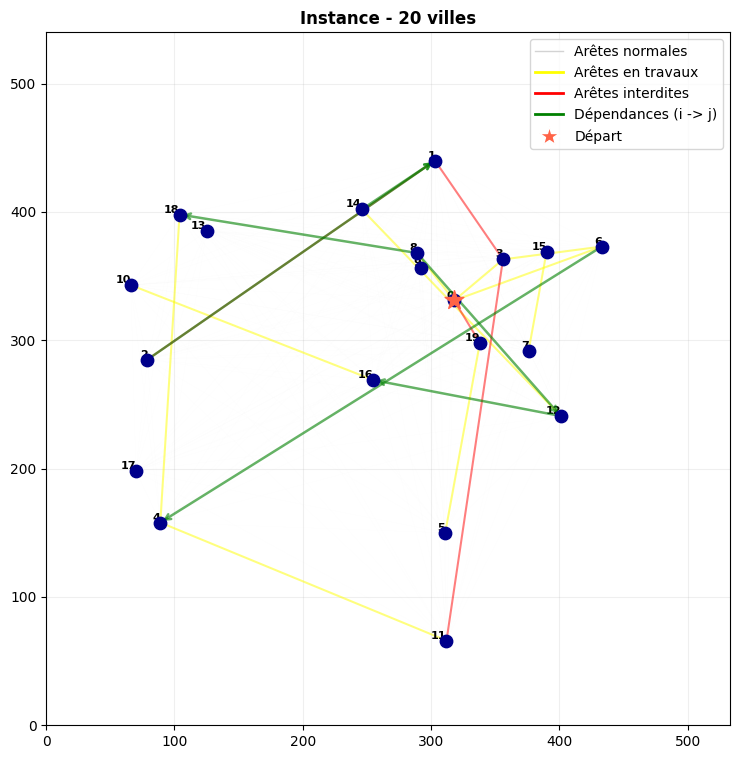

In [11]:
n = 20
coords, dist, aretes_travaux, aretes_interdites, dependances = generer_instance(
    n=n,
    pct_travaux=0.05,
    pct_interdites=0.02,
    pct_dependances=0.3,
    coef_travaux_min=1.0,
    coef_travaux_max=2.0,
    coef_interdit_min=10000,
    coef_interdit_max=100000,
    seed=None,
)

print(f"Instance générée : {n} villes")
print(f"Nombre total d'arêtes : {n * (n - 1) // 2}")
print(f"Nombre d'arêtes en travaux : {len(aretes_travaux)}")
print(f"Nombre d'arêtes interdites : {len(aretes_interdites)}")
print(f"Nombre de dépendances : {len(dependances)}")
print(f"Dépendances : {dependances}")
print(f"Coordonnées : {coords}")

afficher_instance(coords, aretes_travaux, aretes_interdites, dependances)
plt.show()

Statut : Optimal
Coût optimal : 156387.00
Tournée : [0, 9, 8, 3, 15, 6, 12, 7, 19, 16, 5, 11, 4, 17, 2, 10, 18, 13, 14, 1, 0]
Temps de résolution : 10.6690 s
Aucune arête interdite utilisée
Toutes les dépendances sont respectées


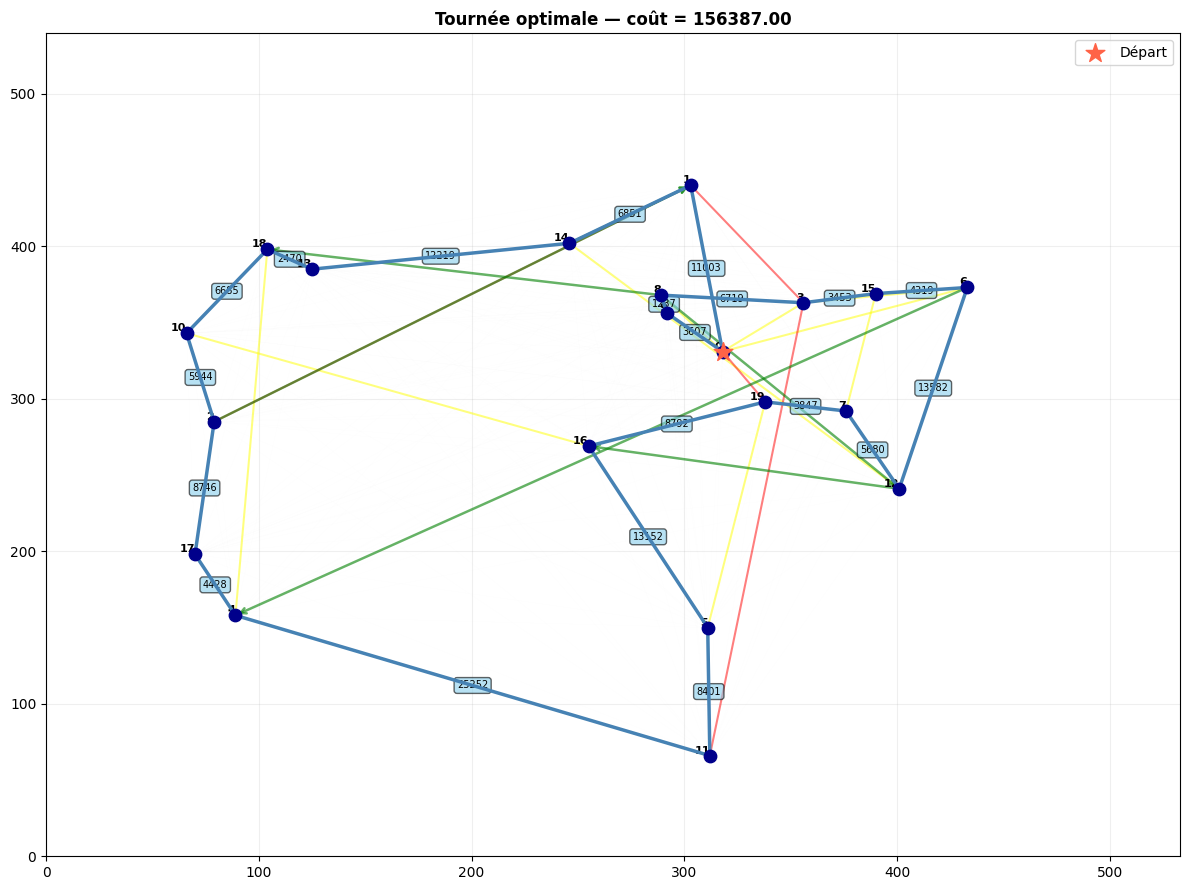

In [12]:
tournee, cout, duree = resoudre_tsp_plne(dist, coords, aretes_travaux, aretes_interdites, dependances)

if tournee is not None:
    afficher_tournee(coords, tournee, dist, couts=dist, aretes_travaux=aretes_travaux,
                    aretes_interdites=aretes_interdites, dependances=dependances, cout=cout)

IntProgress(value=0, layout=Layout(width='100%'), max=20)


RÉSULTATS - Complexité de la résolution exacte
 n Temps moyen (s) Temps min (s) Temps max (s)  Arêtes
10          0.3077        0.1204        0.8018      45
15          3.3630        0.9595        9.2909     105
20         33.1863        1.4415      149.7836     190
25        164.9065       37.6307      530.3321     300


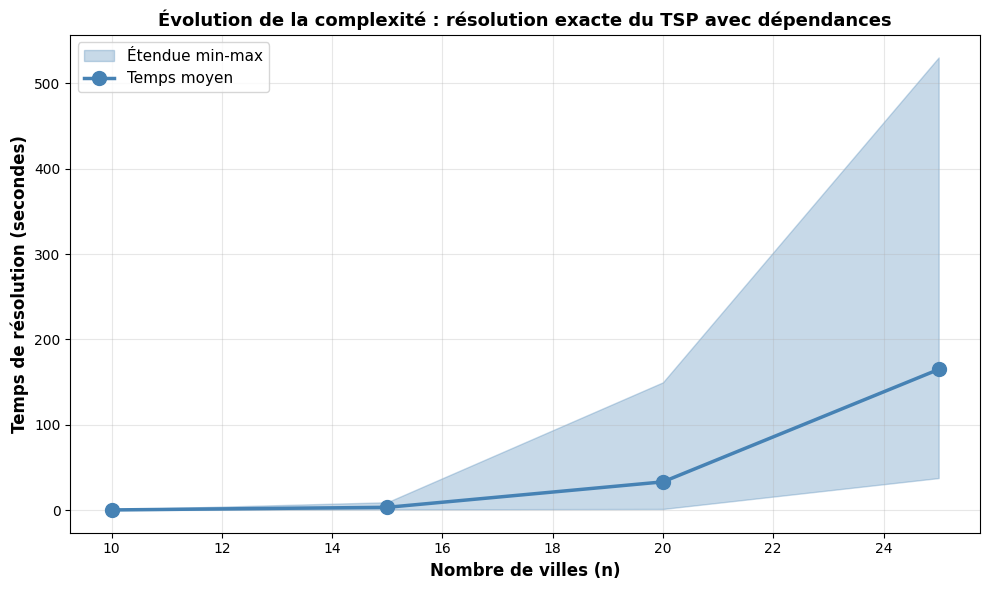

In [10]:
df = orchestrer_benchmarks(
    tailles_n=[10, 15, 20, 25],
    nb_instances_par_taille=5,
    pct_travaux=0.05,
    pct_interdites=0.02,
    pct_dependances=0.10
)